# Ravat et al. (2020): local data versus full SHTOOLS expansion

This notebook uses only the files already in `data/Ravat_etal_2020/`. It makes no network requests. Expand every degree and order in `LP1999_L1_d450.cof` using SHTOOLS and compare with the downloaded global surface-field DAT file. The local coefficients reach degree 450, the maximum degree of the SHTOOLS Ravat2020 dataset. There is no independent second coefficient set in this folder; the SHTOOLS dataset loader is therefore not called.

Source documentation: https://uknowledge.uky.edu/ees_data/2/ and https://doi.org/10.1029/2019JE006187.

Fields are Br (outward), Btheta (southward), Bphi (eastward), and magnitude, in nT. Synthesis uses geocentric latitude on an ellipsoid with equatorial radius 1738.1 km and polar radius 1736.0 km. The local COF header specifies magnetic potential at **1737.4 km**, through degree/order **450**, and requires evaluation of all terms to avoid ringing. SHTOOLS reads the reference radius directly from the numeric header after skipping eight descriptive lines; the evaluation ellipsoid remains 1738.1 km by 1736.0 km. Schmidt normalization and no Condon–Shortley phase follow the SHTOOLS SHMagCoeffs file-reader defaults for this dataset. The radius sensitivity diagnostic illustrates radial scaling; it does not calibrate the model to the field data.

All coefficients are retained. Default comparison spacing is 0.5°; use 0.1° for all non-polar, non-duplicate nodes. Synthesis always uses the full degree 450 at exact 0.1° grid nodes, without interpolation. Poles and duplicate longitude 360° are omitted. Allow several minutes and approximately 1–2 GB RAM.

The header flattening is rounded to 0.0012, implying a polar radius of 1736.01428 km. For comparison with the DAT product, use its documented polar radius of 1736.0 km (14.28 m difference); retain both values in provenance.

In [1]:
# Run once in the notebook's kernel if needed, then restart the kernel:
# %pip install numpy pandas matplotlib pyshtools nbformat
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyshtools as pysh
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook inside the GravMagPy repository.')
DATA = ROOT / 'data' / 'Ravat_etal_2020'
OUT = DATA / 'comparison_outputs'
OUT.mkdir(parents=True, exist_ok=True)
COMPARE_STEP_DEG = 0.5  # 0.1 gives the complete non-polar grid
SOURCE_STEP_DEG = 0.1
A_M, B_M = 1738100.0, 1736000.0
F = (A_M - B_M) / A_M
FIELD_NAME = 'Ravatetal_JGR2020_LunarL1MagneticModelFields_LPgrad.dat'
FIELD_PATH = DATA / FIELD_NAME
COF_PATH = DATA / 'LP1999_L1_d450.cof'
PAGE = 'https://uknowledge.uky.edu/ees_data/2/'
print('pyshtools:', pysh.__version__, '\nData directory:', DATA)

pyshtools: 4.14.1 
Data directory: /Users/danywaller/code/GravMagPy/data/Ravat_etal_2020


## Verify local inputs
No data or coefficients are downloaded. Missing files produce a local file error.

In [2]:
for path in (FIELD_PATH, COF_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)
    print(path.name, f'{path.stat().st_size / 1024**2:.1f} MiB')

Ravatetal_JGR2020_LunarL1MagneticModelFields_LPgrad.dat 340.2 MiB
LP1999_L1_d450.cof 4.1 MiB


In [3]:
# Stream the large ASCII file; retain only requested comparison nodes.
stride = int(round(COMPARE_STEP_DEG / SOURCE_STEP_DEG))
if stride < 1 or not np.isclose(stride * SOURCE_STEP_DEG, COMPARE_STEP_DEG):
    raise ValueError('Comparison step must be a positive multiple of 0.1 degrees.')
names = ['lon', 'lat', 'Br', 'Btheta', 'Bphi', 'Btotal']
parts = []
row_count = 0
for chunk in pd.read_csv(FIELD_PATH, sep=r'\s+', header=None, names=names,
                         chunksize=250_000, dtype=np.float64):
    row_count += len(chunk)
    lon, lat = chunk.lon.to_numpy(), chunk.lat.to_numpy()
    keep = (np.isclose(lon / COMPARE_STEP_DEG, np.round(lon / COMPARE_STEP_DEG), atol=1e-7, rtol=0)
            & np.isclose(lat / COMPARE_STEP_DEG, np.round(lat / COMPARE_STEP_DEG), atol=1e-7, rtol=0)
            & (lon >= 0) & (lon < 360) & (np.abs(lat) < 90))
    parts.append(chunk.loc[keep])
observed = pd.concat(parts, ignore_index=True).sort_values(['lat', 'lon']).reset_index(drop=True)
del parts, chunk
assert row_count == 6_485_401, f'Unexpected global grid row count: {row_count}'
assert np.isfinite(observed.to_numpy()).all()
assert not observed.duplicated(['lat', 'lon']).any()
expected = (round(180 / COMPARE_STEP_DEG) - 1) * round(360 / COMPARE_STEP_DEG)
assert len(observed) == expected, (len(observed), expected)
print(f'Read {row_count:,} rows; comparing {len(observed):,} unique non-polar nodes.')
print('Max published |B| consistency error (nT):',
      np.max(np.abs(np.linalg.norm(observed[['Br','Btheta','Bphi']], axis=1) - observed.Btotal)))

Read 6,485,401 rows; comparing 258,480 unique non-polar nodes.
Max published |B| consistency error (nT): 0.0012581087800409563


## Read all local coefficients
Read and check every degree/order pair, without a dataset-loader download or degree truncation.
Read the metadata using `SHMagCoeffs.from_file(skip=8, header=True, header_units="km")`, matching the file instructions. Check the numeric coefficient block separately for completeness.

In [4]:
if not COF_PATH.exists():
    raise FileNotFoundError(COF_PATH)
rows = np.loadtxt(COF_PATH, skiprows=9)
ell, order = rows[:, 0].astype(int), rows[:, 1].astype(int)
assert rows.shape[1] == 4 and np.all(rows[:, :2] == np.column_stack([ell, order]))
assert np.all((ell >= 1) & (order >= 0) & (order <= ell))
local_lmax = int(ell.max())
assert len(set(zip(ell, order))) == len(rows) == (local_lmax + 1)*(local_lmax + 2)//2 - 1
local = pysh.SHMagCoeffs.from_file(COF_PATH, skip=8, header=True,
    header_units='km', lmax=None, normalization='schmidt', csphase=1,
    file_units='nT', units='nT')
header_radius_km, header_flattening, header_a_km, header_degree, header_order = map(float, local.header)
assert local.lmax == local_lmax == int(header_degree)
assert int(order.max()) == int(header_order)
assert np.isclose(A_M, header_a_km * 1000)
REFERENCE_RADIUS_M = local.r0
print('Header flattening:', header_flattening,
      '| DAT ellipsoid flattening:', F,
      '| Header-implied polar radius (km):', header_a_km * (1-header_flattening))
print('Full local coefficient degree:', local.lmax)
print('Model reference radius (m):', local.r0, '| Convention:', local.normalization, local.csphase)

Header flattening: 0.0012 | DAT ellipsoid flattening: 0.0012082158679017317 | Header-implied polar radius (km): 1736.0142799999999
Full local coefficient degree: 450
Model reference radius (m): 1737400.0 | Convention: schmidt 1


In [5]:
# The output grid is oversampled to match the published 0.1-degree nodes.
# lmax controls grid size; lmax_calc controls the actual coefficient bandwidth.
GRID_LMAX = int(round(90 / SOURCE_STEP_DEG)) - 1

def synthesize(model):
    if model.lmax > GRID_LMAX:
        raise ValueError('Model bandwidth exceeds output grid; increase grid resolution.')
    grid = model.expand(a=A_M, f=F, lmax=GRID_LMAX,
                        lmax_calc=model.lmax, sampling=2, extend=False)
    ilat = np.rint((90 - observed.lat.to_numpy()) / SOURCE_STEP_DEG).astype(int)
    ilon = np.rint(observed.lon.to_numpy() / SOURCE_STEP_DEG).astype(int)
    assert np.allclose(grid.rad.lats()[ilat], observed.lat, atol=1e-8)
    assert np.allclose(grid.rad.lons()[ilon], observed.lon, atol=1e-8)
    result = np.column_stack([g.data[ilat, ilon] for g in
                             (grid.rad, grid.theta, grid.phi, grid.total)])
    assert np.isfinite(result).all()
    return result

predictions = {}
for label, model in [('Local LP1999', local)]:
    print('Synthesizing', label, 'through degree', model.lmax, flush=True)
    predictions[label] = synthesize(model)
print('Full local expansion complete.')

Synthesizing Local LP1999 through degree 450
Full local expansion complete.


In [6]:
# Independently check grid synthesis at scattered nodes, and report radius sensitivity.
indices = np.linspace(0, len(observed)-1, 100, dtype=int)
points = observed.iloc[indices]
lat_rad = np.deg2rad(points.lat.to_numpy())
radius = A_M * B_M / np.sqrt((B_M*np.cos(lat_rad))**2 + (A_M*np.sin(lat_rad))**2)
cilm = local.to_array(normalization='schmidt', csphase=1)
checks = []
for r0 in [1736000., 1737100., 1737400., 1738100.]:
    values = np.array([pysh.gravmag.MakeMagGridPoint(cilm, r0, r, lat, lon, lmax=local.lmax)
                       for r, lat, lon in zip(radius, points.lat, points.lon)])
    difference = values - points[['Br', 'Btheta', 'Bphi']].to_numpy()
    checks.append({'reference_radius_km': r0/1000, 'sample_vector_rmse_nT': np.sqrt(np.mean(np.sum(difference**2, axis=1)))})
    if r0 == REFERENCE_RADIUS_M:
        error = np.max(np.abs(values - predictions['Local LP1999'][indices, :3]))
        print('Max grid versus point synthesis difference (nT):', error)
        assert error < 1e-6
radius_sensitivity = pd.DataFrame(checks)
display(radius_sensitivity)
radius_sensitivity.to_csv(OUT / 'reference_radius_sensitivity.csv', index=False)


Max grid versus point synthesis difference (nT): 1.4948042803553108e-12
   reference_radius_km  sample_vector_rmse_nT
0               1736.0               1.077443
1               1737.1               0.605458
2               1737.4               0.565161
3               1738.1               0.778840


## Residual statistics and maps
Residuals are **expansion minus published field**. Metrics use cosine-of-geocentric-latitude weights (solid-angle weighting, not exact ellipsoid area). Poles are omitted because the horizontal component basis is singular there; longitude 360° is omitted because it duplicates 0°. Map colour limits use the 99th percentile for visibility; statistics use all retained values, including extremes. Residuals against the published equivalent-source field can reflect finite harmonic bandwidth, coefficient rounding, and coordinate conventions.

In [7]:
components = ['Br', 'Btheta', 'Bphi', 'Btotal']
truth = observed[components].to_numpy()
w = np.cos(np.deg2rad(observed.lat.to_numpy()))
records = []
comparisons = [(label + ' − published', pred, truth) for label, pred in predictions.items()]

for label, pred, ref in comparisons:
    for j, component in enumerate(components):
        d = pred[:, j] - ref[:, j]
        records.append(dict(comparison=label, component=component,
            bias_nT=np.average(d, weights=w),
            rmse_nT=np.sqrt(np.average(d*d, weights=w)),
            mae_nT=np.average(np.abs(d), weights=w), max_abs_nT=np.max(np.abs(d))))
metrics = pd.DataFrame(records)
display(metrics)
metrics.to_csv(OUT / 'residual_metrics.csv', index=False)

                 comparison component   bias_nT   rmse_nT    mae_nT  max_abs_nT
0  Local LP1999 − published        Br  0.066061  0.568525  0.284740   30.991552
1  Local LP1999 − published    Btheta  0.000122  0.403646  0.203545   17.961091
2  Local LP1999 − published      Bphi -0.000071  0.390749  0.198890   16.049640
3  Local LP1999 − published    Btotal -0.061305  0.671737  0.304364   36.840831


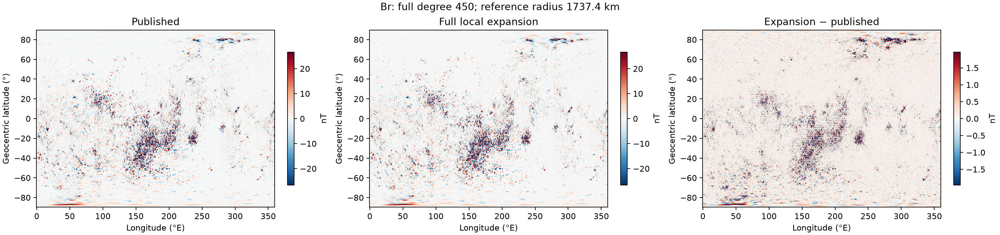

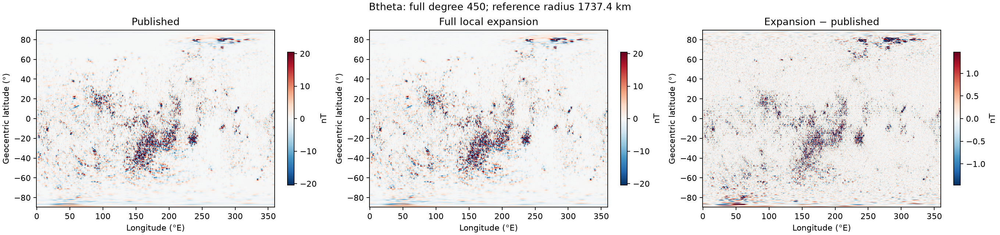

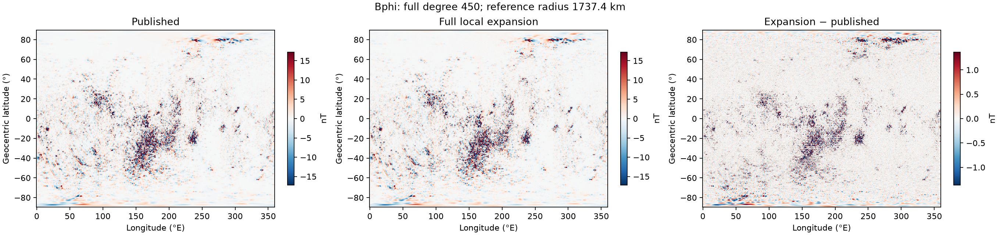

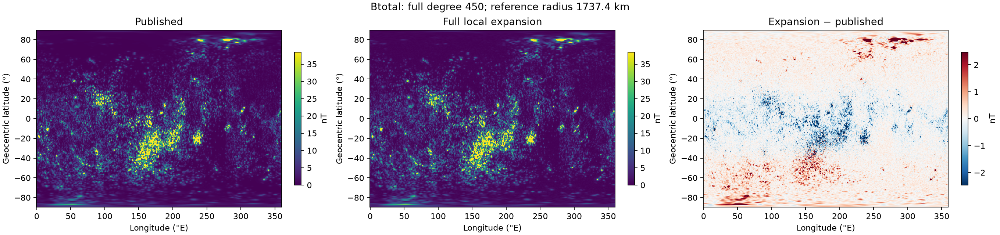

In [8]:
lats, lons = np.sort(observed.lat.unique()), np.sort(observed.lon.unique())
def image(values):
    return np.asarray(values).reshape(len(lats), len(lons))
for j, component in enumerate(components):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
    field_limit = max(np.percentile(np.abs(truth[:, j]), 99), 1e-12)
    panels = [('Published', truth[:, j]),
              ('Full local expansion', predictions['Local LP1999'][:, j]),
              ('Expansion − published', predictions['Local LP1999'][:, j] - truth[:, j])]
    for k, (ax, (title, values)) in enumerate(zip(axes, panels)):
        limit = field_limit if k < 2 else max(np.percentile(np.abs(values), 99), 1e-12)
        total = component == 'Btotal' and k < 2
        im = ax.pcolormesh(lons, lats, image(values), shading='auto',
                          cmap='viridis' if total else 'RdBu_r',
                          vmin=0 if total else -limit, vmax=limit, rasterized=True)
        ax.set(title=title, xlabel='Longitude (°E)', ylabel='Geocentric latitude (°)')
        fig.colorbar(im, ax=ax, label='nT', shrink=0.75)
    fig.suptitle(f'{component}: full degree {local.lmax}; reference radius {local.r0/1000:g} km')
    fig.savefig(OUT / f'{component}_comparison.png', dpi=160)
    plt.show()


## Evaluation-surface diagnostic: sphere versus ellipsoid

Keep the **same coefficients, reference radius, all degree/order terms through 450, and comparison nodes**. Change only the evaluation surface: the documented 1738.1 × 1736.0 km ellipsoid versus a sphere at the coefficient reference radius of 1737.4 km. Residuals are expansion minus published magnitude.

At the equator the ellipsoid lies 0.7 km outside that sphere, attenuating high-degree fields; at the poles it lies 1.4 km inside, amplifying them. Each degree's magnetic field scales as `r**(-(degree+2))`. This can create negative equatorial and positive polar magnitude residuals. The sphere test isolates that effect without fitting any parameter to the data.

If the sphere removes the broad latitude pattern and reduces RMSE, this is evidence of a surface-convention mismatch. It does **not** prove which surface was used to generate the published DAT, whose documentation specifies an ellipsoid. Remaining errors can include finite bandwidth and coefficient rounding. The original ellipsoid comparison is retained unchanged.

In [13]:
sphere_grid = local.expand(a=local.r0, f=0.0, lmax=GRID_LMAX,
                           lmax_calc=local.lmax, sampling=2, extend=False)
surface_i = np.rint((90-observed.lat.to_numpy()) / SOURCE_STEP_DEG).astype(int)
surface_j = np.rint(observed.lon.to_numpy() / SOURCE_STEP_DEG).astype(int)
assert np.allclose(sphere_grid.total.lats()[surface_i], observed.lat)
assert np.allclose(sphere_grid.total.lons()[surface_j], observed.lon)
sphere_prediction = np.column_stack([g.data[surface_i, surface_j] for g in
    (sphere_grid.rad, sphere_grid.theta, sphere_grid.phi, sphere_grid.total)])
del sphere_grid
ellipsoid_prediction = predictions['Local LP1999']
surface_comparison = observed[['lon','lat']].copy()
surface_comparison['published_nT'] = observed.Btotal.to_numpy()
surface_comparison['ellipsoid_residual_nT'] = ellipsoid_prediction[:,3] - observed.Btotal.to_numpy()
surface_comparison['sphere_residual_nT'] = sphere_prediction[:,3] - observed.Btotal.to_numpy()
surface_comparison['ellipsoid_minus_sphere_nT'] = ellipsoid_prediction[:,3] - sphere_prediction[:,3]
assert np.isfinite(sphere_prediction).all()


In [14]:
surface_weights = np.cos(np.deg2rad(observed.lat.to_numpy()))
surface_rows = []
for label, prediction in [('Ellipsoid 1738.1 × 1736.0 km', ellipsoid_prediction),
                          ('Sphere 1737.4 km', sphere_prediction)]:
    for j, component in enumerate(components):
        difference = prediction[:,j] - observed[component].to_numpy()
        surface_rows.append(dict(surface=label, component=component,
            bias_nT=np.average(difference, weights=surface_weights),
            rmse_nT=np.sqrt(np.average(difference*difference, weights=surface_weights)),
            mae_nT=np.average(np.abs(difference), weights=surface_weights),
            max_abs_nT=np.max(np.abs(difference))))
surface_metrics = pd.DataFrame(surface_rows)
display(surface_metrics)
surface_comparison['latitude_band'] = pd.cut(surface_comparison.lat, [-90,-60,-30,0,30,60,90])
surface_columns = ['ellipsoid_residual_nT','sphere_residual_nT','ellipsoid_minus_sphere_nT']
surface_band_means = surface_comparison.groupby('latitude_band', observed=True)[surface_columns].mean()
surface_latitude_means = surface_comparison.groupby('lat')[surface_columns].mean()
print('Longitude means by latitude band (nT):')
display(surface_band_means)
print('Total-field area-weighted RMSE (nT):')
display(surface_metrics.loc[surface_metrics.component == 'Btotal', ['surface','rmse_nT']])
surface_metrics.to_csv(OUT / 'evaluation_surface_metrics.csv', index=False)
surface_band_means.to_csv(OUT / 'evaluation_surface_latitude_bands.csv')
surface_latitude_means.to_csv(OUT / 'evaluation_surface_latitude_profiles.csv')
surface_comparison.to_csv(OUT / 'evaluation_surface_samples.csv.gz', index=False)


                        surface component  ...    mae_nT  max_abs_nT
0  Ellipsoid 1738.1 × 1736.0 km        Br  ...  0.284740   30.991552
1  Ellipsoid 1738.1 × 1736.0 km    Btheta  ...  0.203545   17.961091
2  Ellipsoid 1738.1 × 1736.0 km      Bphi  ...  0.198890   16.049640
3  Ellipsoid 1738.1 × 1736.0 km    Btotal  ...  0.304364   36.840831
4              Sphere 1737.4 km        Br  ...  0.225899   13.225006
5              Sphere 1737.4 km    Btheta  ...  0.150390    8.899468
6              Sphere 1737.4 km      Bphi  ...  0.157043    8.678645
7              Sphere 1737.4 km    Btotal  ...  0.187881   16.616806

[8 rows x 6 columns]
Longitude means by latitude band (nT):
               ellipsoid_residual_nT  ...  ellipsoid_minus_sphere_nT
latitude_band                         ...                           
(-90, -60]                  0.285622  ...                   0.242171
(-60, -30]                  0.176991  ...                   0.146021
(-30, 0]                   -0.339218  ... 

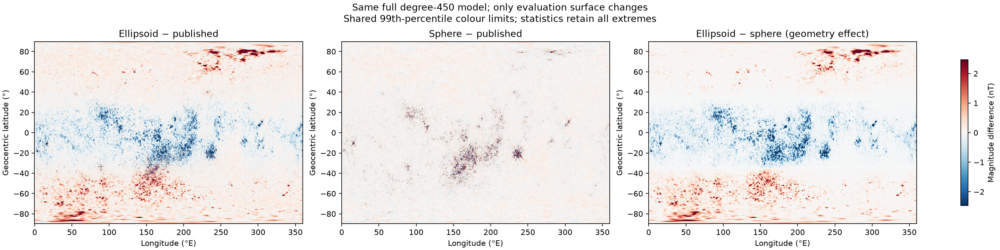

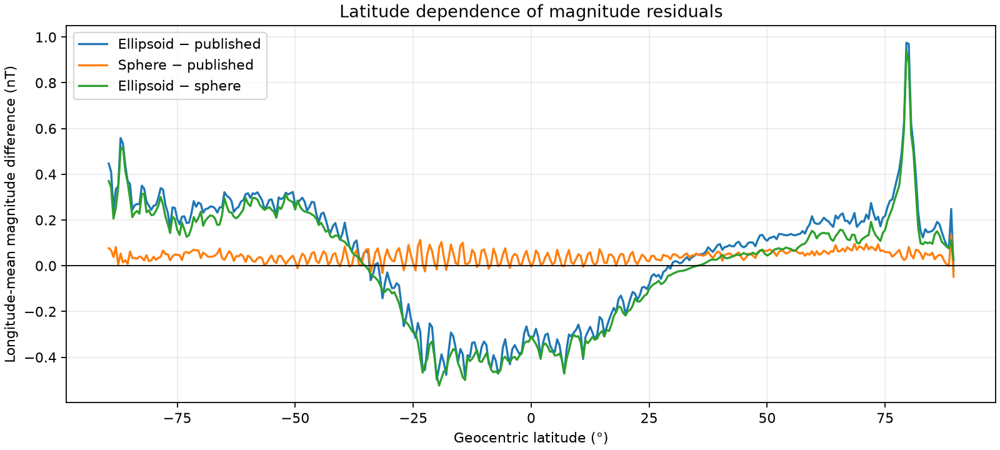

In [15]:
# Matched map scales make the latitude pattern directly comparable.
surface_lats = np.sort(observed.lat.unique())
surface_lons = np.sort(observed.lon.unique())
surface_shape = (len(surface_lats), len(surface_lons))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
map_limit = max(float(np.percentile(np.abs(surface_comparison[c]),99)) for c in surface_columns)
map_limit = max(map_limit, 1e-12)
for ax, column, title in zip(axes, surface_columns,
    ['Ellipsoid − published', 'Sphere − published', 'Ellipsoid − sphere (geometry effect)']):
    im = ax.pcolormesh(surface_lons, surface_lats,
        surface_comparison[column].to_numpy().reshape(surface_shape), shading='auto',
        cmap='RdBu_r', vmin=-map_limit, vmax=map_limit, rasterized=True)
    ax.set(title=title, xlabel='Longitude (°E)', ylabel='Geocentric latitude (°)')
fig.colorbar(im, ax=axes, label='Magnitude difference (nT)', shrink=0.8)
fig.suptitle('Same full degree-450 model; only evaluation surface changes\nShared 99th-percentile colour limits; statistics retain all extremes')
fig.savefig(OUT / 'evaluation_surface_residual_maps.png', dpi=160)
plt.show()
fig, ax = plt.subplots(figsize=(10,4.5), constrained_layout=True)
for column, label in zip(surface_columns,
    ['Ellipsoid − published', 'Sphere − published', 'Ellipsoid − sphere']):
    ax.plot(surface_latitude_means.index, surface_latitude_means[column], label=label)
ax.axhline(0, color='black', lw=0.8)
ax.set(xlabel='Geocentric latitude (°)', ylabel='Longitude-mean magnitude difference (nT)',
       title='Latitude dependence of magnitude residuals')
ax.legend()
ax.grid(alpha=0.25)
fig.savefig(OUT / 'evaluation_surface_latitude_profiles.png', dpi=160)
plt.show()


In [9]:
# Preserve comparison samples and provenance for reproducibility.
result = observed.copy()
for label, prefix in [('Local LP1999', 'local')]:
    for j, component in enumerate(components):
        result[f'{prefix}_{component}_nT'] = predictions[label][:, j]
result.to_csv(OUT / 'comparison_samples.csv.gz', index=False)
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as src:
        for block in iter(lambda: src.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()
provenance = dict(source=PAGE, pyshtools_version=pysh.__version__,
    local_lmax=local_lmax, reference_metadata_verified=True, reference_metadata_source="Local COF numeric header after eight descriptive lines",
    reference_radius_m=float(local.r0), normalization=local.normalization,
    csphase=int(local.csphase), units=local.units,
    cof_header=local.header, header_flattening=header_flattening, ellipsoid_a_m=A_M, ellipsoid_b_m=B_M, compare_step_deg=COMPARE_STEP_DEG,
    field_sha256=sha256(FIELD_PATH), local_cof_sha256=sha256(COF_PATH))
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2) + '\n')
print('Saved maps, metrics, comparison samples, and provenance to', OUT)

Saved maps, metrics, comparison samples, and provenance to /Users/danywaller/code/GravMagPy/data/Ravat_etal_2020/comparison_outputs


## Reiner Gamma: regional L2resL1 model versus global representations

Use the downloaded `Ravatetal2020_LunarL2resL1_ReinerGamma_Brtptot.dat` at its native 0.1° spacing (295–310°E, 0–15°N). Compare three fields at identical nodes:

1. Regional L2resL1 surface model, with regional source spacing and regularization.
2. Published global equivalent-source surface field from the global DAT.
3. Full degree-450 synthesis of the global COF on the DAT ellipsoid.

Differences are **regional minus global**. The first difference measures regional versus global modeling; the second also includes the global model's finite harmonic representation. Neither is an observational error estimate. Each figure shows Regional L2resL1, Global SH degree 450, and the residual Regional L2resL1 minus Global SH degree 450 in one row. Field panels share full-range colour limits; residuals use a separate symmetric scale centred on zero. No percentile clipping is applied. Tables retain the comparisons with both global representations. Statistics use cosine latitude weights and include all native regional nodes. These regional data contain six columns; no undocumented seventh column is assumed.

In [10]:
RG_PATH = DATA / 'Ravatetal2020_LunarL2resL1_ReinerGamma_Brtptot.dat'
if not RG_PATH.is_file():
    raise FileNotFoundError(RG_PATH)
rg_array = np.loadtxt(RG_PATH)
assert rg_array.ndim == 2 and rg_array.shape[1] == 6
assert np.isfinite(rg_array).all()
rg_names = ['lon', 'lat', 'Br', 'Btheta', 'Bphi', 'Btotal']
rg = pd.DataFrame(rg_array, columns=rg_names).sort_values(['lat', 'lon']).reset_index(drop=True)
assert not rg.duplicated(['lat', 'lon']).any()
rg_lats, rg_lons = np.sort(rg.lat.unique()), np.sort(rg.lon.unique())
assert len(rg) == len(rg_lats)*len(rg_lons)
rg_components = rg_names[2:]
rg_bounds = (rg.lon.min(), rg.lon.max(), rg.lat.min(), rg.lat.max())
print('Regional nodes:', len(rg), '| Bounds (lon min/max, lat min/max):', rg_bounds)
print('Regional reported-total versus vector-norm maximum discrepancy (nT):',
      np.max(np.abs(np.linalg.norm(rg[rg_components[:3]], axis=1)-rg.Btotal)))

# Read the full-resolution global crop, independent of COMPARE_STEP_DEG.
rg_global_parts = []
for chunk in pd.read_csv(FIELD_PATH, sep=r'\s+', header=None, names=rg_names,
                         dtype=np.float64, chunksize=250_000):
    selected = chunk.lon.between(rg_bounds[0], rg_bounds[1]) & chunk.lat.between(rg_bounds[2], rg_bounds[3])
    rg_global_parts.append(chunk.loc[selected])
rg_global = pd.concat(rg_global_parts, ignore_index=True).sort_values(['lat','lon']).reset_index(drop=True)
del rg_global_parts, chunk
assert np.array_equal(rg_global[['lat','lon']].to_numpy(), rg[['lat','lon']].to_numpy())
assert np.isfinite(rg_global.to_numpy()).all()

# Synthesize the full model, extract exact native nodes, release full grids.
rg_grid = local.expand(a=A_M, f=F, lmax=899, lmax_calc=local.lmax, sampling=2, extend=False)
rg_i = np.rint((90-rg.lat.to_numpy())/0.1).astype(int)
rg_j = np.rint(rg.lon.to_numpy()/0.1).astype(int)
assert np.allclose(rg_grid.rad.lats()[rg_i], rg.lat)
assert np.allclose(rg_grid.rad.lons()[rg_j], rg.lon)
rg_sh = np.column_stack([g.data[rg_i, rg_j] for g in
                         (rg_grid.rad, rg_grid.theta, rg_grid.phi, rg_grid.total)])
del rg_grid
rg_fields = {'Regional L2resL1': rg[rg_components].to_numpy(),
             'Global DAT': rg_global[rg_components].to_numpy(),
             'Global SH degree 450': rg_sh}
assert all(np.isfinite(v).all() for v in rg_fields.values())


Regional nodes: 22801 | Bounds (lon min/max, lat min/max): (np.float64(295.0), np.float64(310.0), np.float64(0.0), np.float64(15.0))
Regional reported-total versus vector-norm maximum discrepancy (nT): 145.75121136495596


### Regional total-field consistency warning

The downloaded regional file's sixth column is **not consistently equal** to `sqrt(Br²+Btheta²+Bphi²)`. The maximum discrepancy is about **145.75 nT**, far above rounding precision. For example, at 301.5°E, 7.2°N the components imply approximately 132.32 nT, while the file reports 278.072 nT. The cause cannot be established from these files alone. Preserve the supplied values, label the Btotal maps as **reported total**, and treat their physical interpretation as provisional. Component maps compare the supplied component columns directly. The table below separately compares **vector magnitudes recomputed from components for all three models**.

In [11]:
rg_magnitude_check = []
rg_derived_magnitudes = {}
for label, values in rg_fields.items():
    derived = np.linalg.norm(values[:,:3], axis=1)
    rg_derived_magnitudes[label] = derived
    mismatch = values[:,3]-derived
    rg_magnitude_check.append(dict(model=label, reported_total_max_nT=values[:,3].max(),
        component_norm_max_nT=derived.max(), max_abs_total_minus_norm_nT=np.max(np.abs(mismatch))))
rg_magnitude_check = pd.DataFrame(rg_magnitude_check)
display(rg_magnitude_check)
rg_magnitude_check.to_csv(OUT / 'reiner_gamma_total_consistency.csv', index=False)
rg_derived_rows = []
for label in ['Global DAT', 'Global SH degree 450']:
    d = rg_derived_magnitudes['Regional L2resL1'] - rg_derived_magnitudes[label]
    rg_derived_rows.append(dict(comparison='Regional − '+label,
        bias_nT=np.average(d,weights=rg_weights) if 'rg_weights' in globals() else np.average(d, weights=np.cos(np.deg2rad(rg.lat))),
        rmse_nT=np.sqrt(np.average(d*d, weights=np.cos(np.deg2rad(rg.lat)))),
        max_abs_nT=np.max(np.abs(d))))
rg_derived_metrics = pd.DataFrame(rg_derived_rows)
display(rg_derived_metrics)
rg_derived_metrics.to_csv(OUT / 'reiner_gamma_component_norm_metrics.csv', index=False)


                  model  ...  max_abs_total_minus_norm_nT
0      Regional L2resL1  ...                 1.457512e+02
1            Global DAT  ...                 1.268813e-03
2  Global SH degree 450  ...                 2.842171e-14

[3 rows x 4 columns]
                        comparison   bias_nT    rmse_nT  max_abs_nT
0            Regional − Global DAT  6.815010  16.864138  313.427103
1  Regional − Global SH degree 450  7.152738  17.655721  322.806326


In [12]:
rg_weights = np.cos(np.deg2rad(rg.lat.to_numpy()))
rg_extrema, rg_metric_rows = [], []
for label, values in rg_fields.items():
    for j, component in enumerate(rg_components):
        low, high = np.argmin(values[:,j]), np.argmax(values[:,j])
        rg_extrema.append(dict(model=label, component=component,
            min_nT=values[low,j], max_nT=values[high,j],
            max_lon_deg=rg.lon.iloc[high], max_lat_deg=rg.lat.iloc[high]))
for label in ['Global DAT', 'Global SH degree 450']:
    difference = rg_fields['Regional L2resL1'] - rg_fields[label]
    for j, component in enumerate(rg_components):
        d = difference[:,j]
        rg_metric_rows.append(dict(comparison='Regional − ' + label, component=component,
            bias_nT=np.average(d, weights=rg_weights),
            rmse_nT=np.sqrt(np.average(d*d, weights=rg_weights)),
            mae_nT=np.average(np.abs(d), weights=rg_weights), max_abs_nT=np.max(np.abs(d))))
rg_extrema = pd.DataFrame(rg_extrema)
rg_metrics = pd.DataFrame(rg_metric_rows)
display(rg_extrema, rg_metrics)
rg_extrema.to_csv(OUT / 'reiner_gamma_extrema.csv', index=False)
rg_metrics.to_csv(OUT / 'reiner_gamma_residual_metrics.csv', index=False)


                   model component  ...  max_lon_deg  max_lat_deg
0       Regional L2resL1        Br  ...        301.6          8.1
1       Regional L2resL1    Btheta  ...        301.7          7.7
2       Regional L2resL1      Bphi  ...        304.7         10.8
3       Regional L2resL1    Btotal  ...        302.0          7.2
4             Global DAT        Br  ...        304.5         11.0
5             Global DAT    Btheta  ...        301.5          7.4
6             Global DAT      Bphi  ...        304.8         10.9
7             Global DAT    Btotal  ...        301.5          7.1
8   Global SH degree 450        Br  ...        304.4         11.0
9   Global SH degree 450    Btheta  ...        301.5          7.4
10  Global SH degree 450      Bphi  ...        304.8         10.9
11  Global SH degree 450    Btotal  ...        301.6          7.1

[12 rows x 6 columns]                         comparison component  ...    mae_nT  max_abs_nT
0            Regional − Global DAT        Br  .

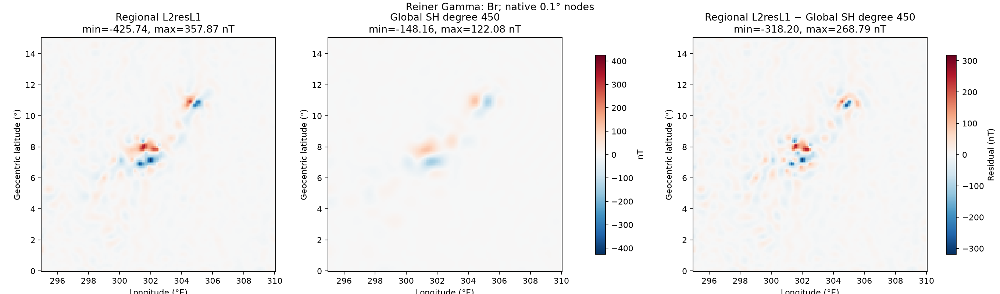

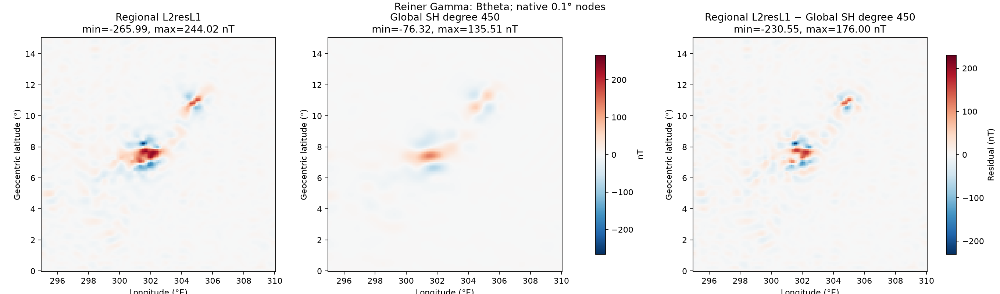

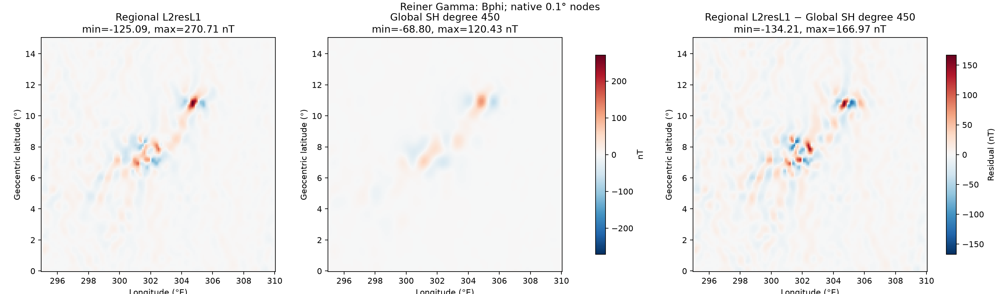

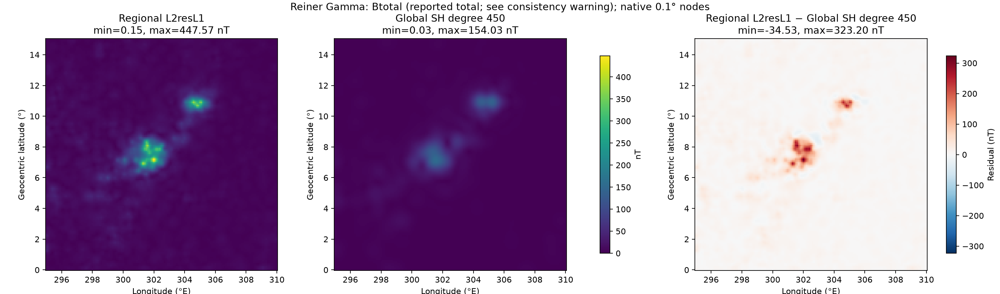

In [13]:
rg_shape = (len(rg_lats), len(rg_lons))
rg_plot_labels = ['Regional L2resL1', 'Global SH degree 450']
for j, component in enumerate(rg_components):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
    limit = max(np.max(np.abs(rg_fields[label][:,j])) for label in rg_plot_labels)
    for ax, label in zip(axes[:2], rg_plot_labels):
        values = rg_fields[label]
        total = component == 'Btotal'
        im = ax.pcolormesh(rg_lons, rg_lats, values[:,j].reshape(rg_shape), shading='auto',
            cmap='viridis' if total else 'RdBu_r', vmin=0 if total else -limit, vmax=limit)
        ax.set(title=f'{label}\nmin={values[:,j].min():.2f}, max={values[:,j].max():.2f} nT',
               xlabel='Longitude (°E)', ylabel='Geocentric latitude (°)', aspect='equal')
    fig.colorbar(im, ax=axes[:2], label='nT', shrink=0.85)
    residual = rg_fields['Regional L2resL1'][:,j] - rg_fields['Global SH degree 450'][:,j]
    residual_limit = max(float(np.max(np.abs(residual))), 1e-12)
    residual_im = axes[2].pcolormesh(rg_lons, rg_lats, residual.reshape(rg_shape),
        shading='auto', cmap='RdBu_r', vmin=-residual_limit, vmax=residual_limit)
    axes[2].set(title=f'Regional L2resL1 − Global SH degree 450\nmin={residual.min():.2f}, max={residual.max():.2f} nT',
        xlabel='Longitude (°E)', ylabel='Geocentric latitude (°)', aspect='equal')
    fig.colorbar(residual_im, ax=axes[2], label='Residual (nT)', shrink=0.85)
    title_component = component + (' (reported total; see consistency warning)' if total else '')
    fig.suptitle(f'Reiner Gamma: {title_component}; native 0.1° nodes')
    fig.savefig(OUT / f'reiner_gamma_{component}_comparison.png', dpi=160)
    plt.show()


In [14]:
rg_output = rg[['lon','lat']].copy()
for label, prefix in [('Regional L2resL1','regional'), ('Global DAT','global_dat'), ('Global SH degree 450','global_sh')]:
    for j, component in enumerate(rg_components):
        rg_output[f'{prefix}_{component}_nT'] = rg_fields[label][:,j]
for label, prefix in [('Global DAT','global_dat'), ('Global SH degree 450','global_sh')]:
    for j, component in enumerate(rg_components):
        rg_output[f'regional_minus_{prefix}_{component}_nT'] = rg_fields['Regional L2resL1'][:,j]-rg_fields[label][:,j]
for label, prefix in [('Regional L2resL1','regional'), ('Global DAT','global_dat'), ('Global SH degree 450','global_sh')]:
    rg_output[f'{prefix}_component_norm_nT'] = rg_derived_magnitudes[label]
rg_output.to_csv(OUT / 'reiner_gamma_comparison_samples.csv.gz', index=False)
rg_provenance = dict(regional_file=RG_PATH.name, regional_sha256=sha256(RG_PATH),
    global_dat_sha256=sha256(FIELD_PATH), global_cof_sha256=sha256(COF_PATH),
    coefficient_lmax=int(local.lmax), reference_radius_m=float(local.r0),
    ellipsoid_a_m=A_M, ellipsoid_b_m=B_M, nodes=len(rg), bounds=list(map(float, rg_bounds)),
    difference_sign='regional minus global', spacing_deg=0.1)
(OUT / 'reiner_gamma_provenance.json').write_text(json.dumps(rg_provenance, indent=2)+'\n')
print('Regional/global comparison saved to', OUT)


Regional/global comparison saved to /Users/danywaller/code/GravMagPy/data/Ravat_etal_2020/comparison_outputs


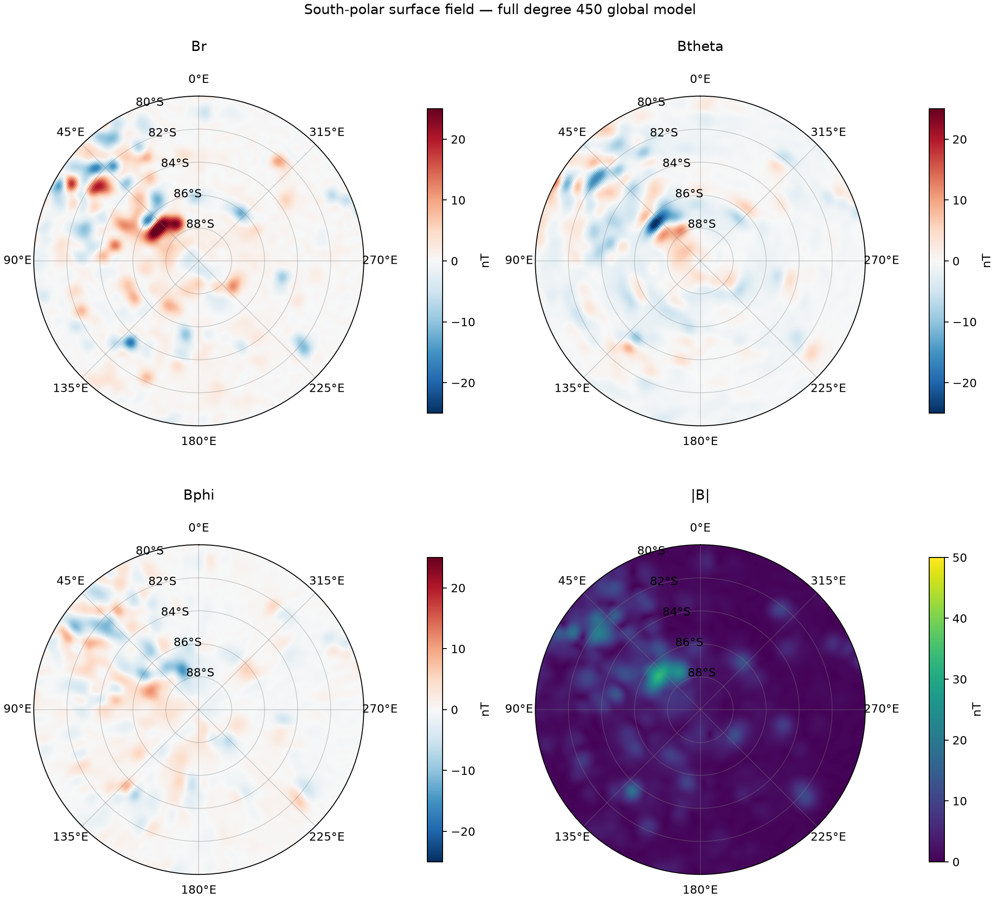

In [17]:
# South-polar surface magnetic field: south-polar stereographic projection.
# Full global SH model on the documented lunar ellipsoid; no downloads.
# Br outward, Btheta southward, Bphi eastward; components remain spherical.
SOUTH_POLAR_LIMIT_DEG = -80.0  # Outer boundary; change to zoom the polar cap.
if not -90 < SOUTH_POLAR_LIMIT_DEG < 0:
    raise ValueError('South-polar boundary must lie between -90 and 0 degrees.')
sp_grid = local.expand(a=A_M, f=F, lmax=899, lmax_calc=local.lmax,
                       sampling=2, extend=False)
sp_lat = sp_grid.rad.lats()
sp_lon = sp_grid.rad.lons()
sp_keep = (sp_lat <= SOUTH_POLAR_LIMIT_DEG) & (sp_lat > -90)
# Sort from the pole outwards. The exact pole is omitted: horizontal basis is singular.
sp_order = np.flatnonzero(sp_keep)[::-1]
sp_lat = sp_lat[sp_order]
sp_fields = [g.data[sp_order, :].copy() for g in
             (sp_grid.rad, sp_grid.theta, sp_grid.phi, sp_grid.total)]
del sp_grid
# Stereographic distance from South Pole (arbitrary common radial scale).
sp_radius = np.tan(np.deg2rad(45 + sp_lat / 2))
sp_outer_radius = np.tan(np.deg2rad(45 + SOUTH_POLAR_LIMIT_DEG / 2))
# Explicit cell edges close the longitude seam and stop exactly at the boundary.
sp_theta_edges = np.deg2rad(np.linspace(-0.05, 359.95, len(sp_lon)+1))
sp_radius_edges = np.r_[0, (sp_radius[:-1]+sp_radius[1:])/2, sp_outer_radius]
sp_ticks_lat = np.arange(-88., SOUTH_POLAR_LIMIT_DEG+0.01, 2.)
sp_ticks_r = np.tan(np.deg2rad(45+sp_ticks_lat/2))
fig, axes = plt.subplots(2, 2, figsize=(12, 11),
                         subplot_kw={'projection':'polar'}, constrained_layout=True)
for ax, name, values in zip(axes.flat, ['Br','Btheta','Bphi','|B|'], sp_fields):
    is_total = name == '|B|'
    limit = 50.0 if is_total else 25.0
    ax.grid(False)
    im = ax.pcolormesh(sp_theta_edges, sp_radius_edges, values,
        shading='flat', cmap='viridis' if is_total else 'RdBu_r',
        vmin=0 if is_total else -limit, vmax=limit, rasterized=True)
    # Seen from above the South Pole: east longitude increases counterclockwise.
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(1)
    ax.set_thetagrids(np.arange(0,360,45), labels=[f'{x}°E' for x in range(0,360,45)])
    ax.set_ylim(0, sp_outer_radius)
    ax.set_yticks(sp_ticks_r, labels=[f'{abs(x):g}°S' for x in sp_ticks_lat])
    ax.set_rlabel_position(22.5)
    ax.grid(color='gray', alpha=0.4, linewidth=0.6)
    ax.set_title(name, pad=20)
    fig.colorbar(im, ax=ax, label='nT', shrink=0.75, pad=0.09)
fig.suptitle(f'South-polar surface field — full degree {local.lmax} global model')
fig.savefig(OUT / 'south_polar_surface_field.png', dpi=180)
plt.show()
